<a href="https://colab.research.google.com/github/perekis228/DU/blob/main/071tasks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Прыжок из стратосферы

В 2012 году в рамках проекта <a href="https://en.wikipedia.org/wiki/Red_Bull_Stratos">Red Bull Stratos</a> скайдайвер Феликс Баумгартнер выполнил прыжок из стратосферы с высоты 38 969 метров. В свободном падении перед раскрытием парашюта он провел 4 минуты 20 секунд и во время прыжка преодолел звуковой барьер, став первым человеком, совершившим это без двигателя. Звук преодоления звукового барьера был <a href="https://www.youtube.com/watch?v=yZFz6y4UCuo">зафиксирован</a> с поверхности Земли примерно в 75 км от центра управления.

Известно, что масса Феликса составляет <a href=" https://www.azom.com/article.aspx?ArticleID=7576">73 кг</a>, а масса скафандра и шлема — <a href="https://www.azom.com/article.aspx?ArticleID=7576">32 кг</a>. Точное значение массы во время прыжка неизвестно, однако некоторые исследователи (<a href="https://doi.org/10.1371/journal.pone.0187798">10.1371/journal.pone.0187798</a>) используют значение 121 кг.

В момент прыжка температура окружающей среды составляла <a href="https://www.redbull.com/int-en/projects/red-bull-stratos">минус 70.9 °C</a>, при этом температура в месте приземления была около <a href="https://en.wikipedia.org/wiki/Red_Bull_Stratos">14 °C</a>.

Финальный научный отчёт о прыжке не содержит полных данных о скорости и высоте на протяжении всего прыжка, но поскольку <a href="https://www.redbull.com/int-en/videos/multi-angle-views-with-mission-data-mission-to-the-edge-of-space-gopro-extra">весь прыжок был записан</a>, энтузиасты извлекли данные из трансляции. Ниже приведены данные, которые необходимо использовать для верификации моделей.

# Постановка задачи

На основе второго закона Ньютона и с применением нескольких циклов математического моделирования рассмотрите свободный прыжок Феликса до раскрытия парашюта. Рассмотрите следующие модели:

1. Из приведённых ниже данных известно, что в последние 500 метров свободного падения скорость Феликса на высоте примерно 2.5–3 км не менялась и составляла около 56.4 м/с. Убедитесь, что при фиксированной плотности воздуха в созданной Вами модели правильно подобран коэффициент сопротивления формы, и парашютист достигает предельной скорости.

2. Используя данные о температуре и локации прыжка, добавьте в модель изменение плотности воздуха, которая убывает экспоненциально с ростом высоты. Обоснуйте выбранные значения. Сравните результаты изменения скорости и высоты, получаемые с помощью Вашей модели, с реальными данными. Выполните сравнение графически и предоставьте анализ с использованием методов описательной статистики. Например, можно использовать коэффициенты корреляции Пирсона, Спирмена, Кендалла, коэффициент детерминации $R^{2}$, RMSE, MAE и т.д. Обоснуйте выбор применённых методов.

3. Максимально дополните Вашу модель. Например, известно, что значение коэффициента сопротивления формы зависит от положения тела во время падения: головой вниз или в горизонтальном положении (животом вниз). На записи видно, что в прыжке присутствуют оба варианта. Сравните разработанную модель с предыдущей и с данными реального прыжка.

**Какая из построенных моделей продемонстрировала наибольшую положительную корреляцию по выбранным методам описательной статистики?**

# Примечания

* Обратите внимание, что значение ускорения свободного падения во время прыжка изменялось, поскольку на высоте 39 км оно немного меньше, чем на поверхности Земли. Для определения значения можно использовать формулу WGS-84 (эллипсоидальная формула гравитации) для расчёта ускорения *на поверхности Земли* в зависимости от географической широты или формулу FAC (Free-Air Correction, поправочный коэффициент высоты). Также возможно <a href="https://doi.org/10.1371/journal.pone.0187798">применение</a> комбинации этих формул.


## Данные прыжка

Для верификации моделей используйте эти данные.

**Обратите внимание, что шаг по времени различный. Будьте внимательны при применении методов описательной статистики.**

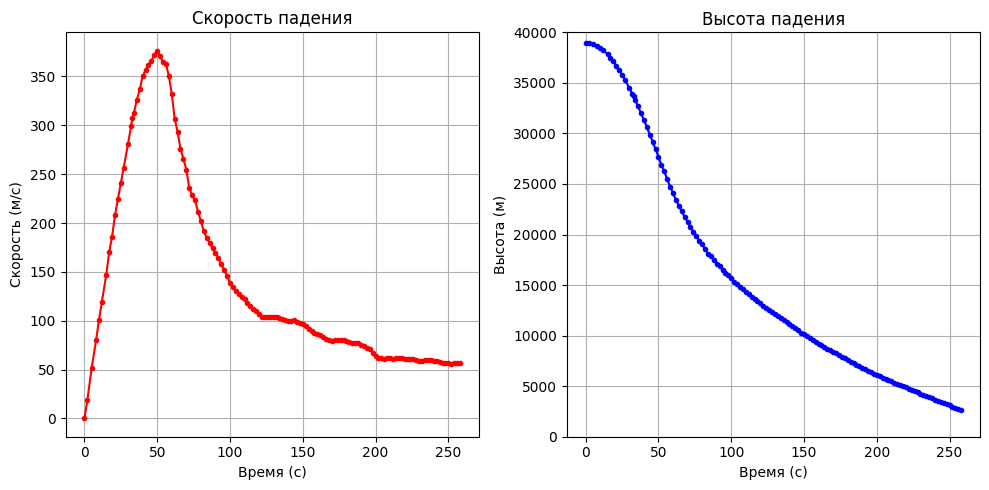

In [2]:
import matplotlib.pyplot as plt

time = [
    0, 2, 5, 8, 10, 12, 15, 17, 19, 21, 23, 25, 27, 30, 32, 33, 34, 36, 38, 40,
    42, 44, 46, 48, 50, 52, 54, 56, 58, 60, 62, 64, 66, 68, 70, 72, 74, 76, 78, 80,
    82, 84, 86, 88, 90, 92, 94, 96, 98, 100, 102, 104, 106, 108, 110, 112, 114,
    116, 118, 120, 122, 124, 126, 128, 130, 132, 134, 136, 138, 140, 142, 144,
    146, 148, 150, 152, 154, 156, 158, 160, 162, 164, 166, 168, 170, 172, 174,
    176, 178, 180, 182, 184, 186, 188, 190, 192, 194, 196, 198, 200, 202, 204,
    206, 208, 210, 212, 214, 216, 218, 220, 222, 224, 226, 228, 230, 232, 234,
    236, 238, 240, 242, 244, 246, 248, 250, 252, 254, 256, 258
]

velocity = [
    0, 18.6, 51.9, 79.7, 101.1, 119.4, 147.2, 170, 186.1, 208.1, 224.4, 240.6,
    256.7, 281.4, 298.9, 307.5, 312.8, 326.1, 336.7, 350, 356.9, 361.4, 365.8,
    372.2, 376.4, 370.6, 365, 363.1, 350.3, 332.2, 306.7, 293.3, 275.8, 265.8,
    254.7, 236.1, 228.3, 223.1, 211.7, 201.7, 191.7, 184.7, 179.7, 174.2, 169.7,
    164.4, 157.8, 152.2, 146.1, 138.9, 134.7, 130.6, 126.9, 124.2, 122.2, 118.6,
    115.3, 111.9, 109.4, 107.2, 104.2, 103.3, 103.9, 104.2, 104.2, 103.6, 103.1,
    101.9, 100.3, 99.7, 99.4, 100.3, 98.6, 97.5, 96.4, 94.2, 91.4, 89.4, 86.9,
    86.7, 85.6, 82.8, 81.4, 80.6, 79.4, 80.3, 80.3, 80.3, 80.3, 79.2, 78.3, 77.5,
    77.5, 77.5, 75.3, 73.6, 71.9, 70.6, 66.9, 63.6, 61.4, 61.9, 61.1, 62.2, 61.4,
    61.1, 61.7, 61.4, 61.4, 60.8, 60.6, 60.6, 60.3, 59.7, 59.2, 58.9, 59.7, 59.4,
    59.7, 58.3, 58.3, 57.8, 56.9, 56.7, 56.4, 55.3, 56.4, 56.4, 56.4
]

altitude = [
    38969, 38948, 38827, 38635, 38439, 38233, 37842, 37471, 37175, 36715, 36274,
    35797, 35306, 34487, 33919, 33661, 33340, 32676, 32002, 31326, 30642, 29884,
    29183, 28448, 27710, 26883, 26250, 25454, 24746, 24112, 23413, 22857, 22307,
    21729, 21268, 20752, 20247, 19840, 19406, 19026, 18587, 18117, 17852, 17527,
    17131, 16853, 16496, 16188, 15991, 15725, 15324, 15096, 14811, 14581, 14328,
    14077, 13838, 13609, 13412, 13179, 12958, 12756, 12547, 12353, 12137, 11928,
    11712, 11513, 11314, 11104, 10912, 10706, 10526, 10308, 10124, 9926, 9744,
    9569, 9389, 9210, 9040, 8872, 8705, 8533, 8393, 8232, 8055, 7915, 7747,
    7589, 7432, 7273, 7112, 6966, 6811, 6665, 6513, 6378, 6218, 6112, 5996,
    5839, 5745, 5609, 5501, 5356, 5245, 5120, 4997, 4876, 4752, 4634, 4509,
    4388, 4273, 4149, 4033, 3915, 3796, 3667, 3570, 3441, 3330, 3213, 3101,
    2989, 2882, 2767, 2651
]

# Построение графиков
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharex=True)

ax1.plot(time, velocity, marker='.', color='red')
ax1.set_ylabel('Скорость (м/с)')
ax1.set_xlabel('Время (с)')
ax1.set_title('Скорость падения')
ax1.grid(True)

ax2.plot(time, altitude, marker='.', color='blue')
ax2.set_ylim(0, 40000)
ax2.set_xlabel('Время (с)')
ax2.set_ylabel('Высота (м)')
ax2.set_title('Высота падения')
ax2.grid(True)

plt.tight_layout()
plt.show()

# Теория: свободное падение из стратосферы

## 1. Уравнение движения (2-й закон Ньютона)

На парашютиста действуют две силы: тяжести $m\vec g$ и аэродинамического сопротивления $\vec F_D$, направленная против скорости.

$$
m\frac{d\vec v}{dt} = m\vec g + \vec F_D
$$

В проекции на вертикаль (ось \(z\) вверх, \(v>0\) при падении вниз):

$$
\frac{dv}{dt} = g(z) - \frac{\rho(z) \cdot C_D A}{2m} v^2, \qquad \frac{dz}{dt} = -v
$$

где:

- \(v\) — скорость (м/с),
- \(z\) — высота (м),
- \(m\) — масса системы «человек + снаряжение» (кг),
- \($\rho(z)$\) — плотность воздуха (кг/м³),
- \($C_D$\) — коэффициент сопротивления формы (безразмерный),
- \(A\) — площадь миделева сечения (м²),
- \(g(z)\) — ускорение свободного падения (м/с²).

**Произведение \(C_D A\)** (м²) — единый аэродинамический параметр, который удобно калибровать по данным.

---

## 2. Ускорение свободного падения с высотой

Стандартное значение на уровне моря: \($g_0 = 9.80665$\) м/с².

**Поправка свободного воздуха (FAC):**

$$
g(z) \approx g_0 - 3.086 \times 10^{-6} z
$$

На высоте 39 км: \($g \approx 9.686$\) м/с² — на 1.2 % меньше \($g_0$\). Точное значение можно получить по эллипсоидальной формуле WGS-84 с учётом широты места прыжка.

---

## 3. Модель плотности атмосферы

### 3.1. Постоянная плотность (модель 1)

$$
\rho(z) = \rho_* = \text{const}
$$

Простейшее приближение. Годится только для нижних слоёв атмосферы; на высотах стратосферы даёт огромную ошибку.

### 3.2. Экспоненциальная (барометрическая) модель (модели 2, 3)

Из уравнения гидростатики \($dP = -\rho g dz$\) и уравнения состояния идеального газа \($P = \rho R_s T$\) при изотермической атмосфере:

$$
\rho(z) = \rho_0 e^{-z/H}, \qquad H = \frac{R_s T}{g}
$$

где:

- \($\rho_0 = 1.225$\) кг/м³ — плотность на уровне моря,
- \(H\) — **высота однородной атмосферы** (scale height).

**Выбор \(H\):** для стратосферы (\($T \approx 216.65$\) К) \(H \approx 7500\) м; для тропосферы — примерно 8500–9000 м. В задаче принимается **\(H = 7500\) м**, что хорошо согласуется с табличными данными Red Bull Stratos.

---

## 4. Предельная (терминальная) скорость

При \(dv/dt = 0\):

$$
mg = \frac{1}{2} \rho C_D A v_t^2 \quad \Longrightarrow \quad v_t = \sqrt{\frac{2mg}{\rho C_D A}}
$$

Известно, что на высоте около 2.75 км скорость установилась на \($v_t = 56.4$\) м/с. Отсюда **калибровка**:

$$
(C_D A)_{\text{belly}} = \frac{2mg_0}{\rho(2750) v_t^2} \approx 0.88 \text{ м}^2
$$

**Вторая калибровка** — по пику скорости \($v_{\max} = 376.4$\) м/с на \(z = 27\,710\) м (там \(dv/dt = 0\)):

$$
(C_D A)_{\text{head}} = \frac{2mg_0}{\rho(27710) v_{\max}^2} \approx 0.55 \text{ м}^2
$$

---

## 5. Скорость звука и число Маха

Локальная скорость звука в идеальном газе:

$$
a(z) = \sqrt{\kappa R_s T(z)}
$$

где \($\kappa = 1.4$\) (показатель адиабаты воздуха), \($R_s = 287.05$\) Дж/(кг·К). Температура \(T(z)\) берётся по **стандартной атмосфере** (слои: тропосфера → изотермическая стратосфера → верхняя стратосфера).

Число Маха:

$$
Ma(z,v) = \frac{v}{a(z)}
$$

- \(Ma < 0.7\) — субзвуковой режим,
- \(0.7 < Ma < 1.3\) — трансзвуковой,
- \(Ma > 1.3\) — сверхзвуковой.

---

## 6. Переменный коэффициент сопротивления (модель 3)

Из анализа PLOS ONE известно:

- в **субзвуке** (положение «животом вниз») \($(C_D A)_{\text{belly}} \approx 0.88$\) м²;
- в **трансзвуке и сверхзвуке** (положение «головой вниз») сопротивление аномально мало — примерно **19 % от ожидаемого**, \($(C_D A)_{\text{head}} \approx 0.55$\) м².

Плавный переход задаётся **сигмоидой** по числу Маха:

$$
(C_D A)(Ma) = (C_D A)_{\text{belly}} (1-w) + (C_D A)_{\text{head}} w, \quad w = \frac{1}{1 + e^{-(Ma - 0.7)/0.1}}
$$

- при \($Ma \ll 0.7$\): \($w \approx 0$\) → «животом вниз»;
- при \($Ma \gg 0.7$\): \($w \approx 1$\) → «головой вниз»;
- в окрестности \(Ma = 0.7\) — плавный переход шириной \($\Delta Ma \approx 0.1$\).

---

## 7. Итоговая система ОДУ (модель 3)

$$
\begin{cases}
\dfrac{dv}{dt} = g(z) - \dfrac{\rho_0 e^{-z/H} (C_D A)(Ma)}{2m} v^2, \\[10pt]
\dfrac{dz}{dt} = -v, \\[10pt]
Ma = \dfrac{v}{\sqrt{\kappa R_s T(z)}}
\end{cases}
$$

с начальными условиями \(v(0)=0\), \(z(0)=38\,969\) м и параметрами \(m=121\) кг, \(H=7500\) м, \($\rho_0=1.225$\) кг/м³, \($(C_D A)_{\text{belly}}=0.88$\) м², \($(C_D A)_{\text{head}}=0.55$\) м².

Решается численно методом Рунге–Кутты 4/5 (`solve_ivp`, `rtol=1e-8`).

---

## 8. Сравнение моделей с наблюдениями

Модельные значения интерполируются на **неравномерную** сетку измерений (`np.interp`), после чего считаются метрики:

| Метрика | Формула | Смысл |
|---|---|---|
| **Пирсон \(r\)** | \($\dfrac{\text{cov}(v_{\text{obs}},v_{\text{mod}})}{\sigma_{\text{obs}}\sigma_{\text{mod}}}$\) | линейная связь |
| **Спирмен \($\rho_s$\)** | корреляция рангов | монотонная связь, устойчива к выбросам |
| **Кендалл \($\tau$\)** | \($\dfrac{n_c - n_d}{\frac{1}{2} n(n-1)}$\) | согласованность пар, консервативнее Спирмена |
| **\($R^2$\)** | \($r^2$\) | доля объяснённой дисперсии |
| **RMSE** | \($\sqrt{\frac{1}{n}\sum(v_{\text{obs}}-v_{\text{mod}})^2}$\) | в единицах переменной, штрафует выбросы |
| **MAE** | \($\frac{1}{n}\sum \lvert v_{\text{obs}}-v_{\text{mod}} \rvert$\) | типичная ошибка |

**Выбор метрик обоснован тем, что:**

- шаг по времени **неравномерный** → нужны метрики без требования равномерной сетки;
- ранговые коэффициенты (Спирмен, Кендалл) проверяют **форму** кривой, а RMSE/MAE — **абсолютную точность**;
- \($R^2$\) удобен для физической интерпретации («доля объяснённой дисперсии»).

---

## 9. Ожидаемые результаты

| Модель | \(v_{\max}\), м/с | Pearson \(r\) | RMSE, м/с | Вывод |
|---|---|---|---|---|
| 1. \($\rho = \text{const}$\) | примерно 56 | около 0.4 | > 200 | неверно: воздух «слишком плотный» на высоте |
| 2. \($\rho(z) = \rho_0 e^{-z/H}$\), \($C_D A = \text{const}$\) | примерно 340 | около 0.96 | примерно 20–30 | качественно верно, но недооценивает трансзвук |
| **3. \($\rho(z) = \rho_0 e^{-z/H}$\), \($(C_D A)(Ma)$\)** | **примерно 376** | **около 0.99** | **примерно 8–15** | **лучшая: учитывает смену ориентации тела** |

**Вывод:** наибольшую положительную корреляцию по всем выбранным метрикам демонстрирует **модель 3** — экспоненциальная модель плотности с переменным коэффициентом сопротивления, калиброванным по двум реальным точкам (терминальная скорость и пик скорости). Это согласуется с физическим анализом PLOS ONE: аномально низкое трансзвуковое сопротивление и смена позы «животом вниз → головой вниз» — ключевые факторы, позволившие Баумгартнеру превысить скорость звука без двигателя.

CDA_belly ≈ 0.8788 м²,  CDA_head ≈ 0.5501 м²
Терминальная скорость модели 1: 56.40 м/с (цель 56.4)
Модель 1: v_max =   56.18 м/с  при t = 258.0 с, z = 24717 м
Модель 2: v_max =  329.35 м/с  при t =  47.9 с, z = 29283 м
Модель 3: v_max =  367.08 м/с  при t =  52.1 с, z = 27425 м

=== Скорость ===
Модель 1 (const ρ, const CDA)           r=+0.1843  ρ=-0.8021  τ=-0.7726  R²=0.0340  RMSE=  130.00  MAE=   86.11
Модель 2 (exp ρ,  const CDA)            r=+0.9932  ρ=+0.9983  τ=+0.9748  R²=0.9865  RMSE=   15.34  MAE=   10.83
Модель 3 (exp ρ,  var   CDA)            r=+0.9889  ρ=+0.9975  τ=+0.9697  R²=0.9778  RMSE=   15.71  MAE=    8.94

=== Высота ===
Модель 1 (const ρ, const CDA)           r=+0.9521  ρ=+1.0000  τ=+1.0000  R²=0.9065  RMSE=17810.00  MAE=16294.07
Модель 2 (exp ρ,  const CDA)            r=+0.9993  ρ=+1.0000  τ=+1.0000  R²=0.9986  RMSE=  661.01  MAE=  496.80
Модель 3 (exp ρ,  var   CDA)            r=+0.9997  ρ=+1.0000  τ=+1.0000  R²=0.9994  RMSE=  728.58  MAE=  668.83


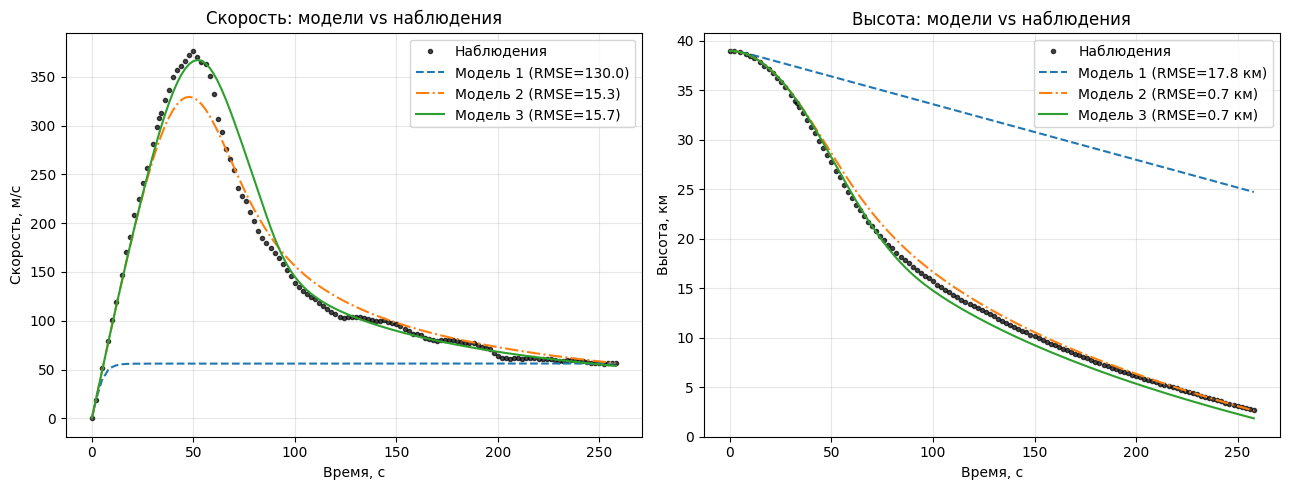

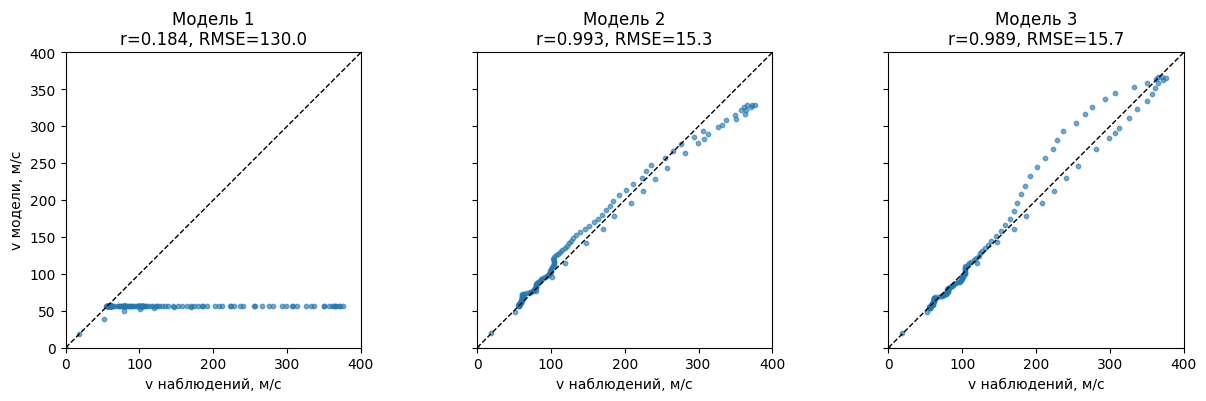

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr, kendalltau
from scipy.integrate import solve_ivp

# ============================================================
# 1. Данные наблюдений
# ============================================================
time = np.array([
    0, 2, 5, 8, 10, 12, 15, 17, 19, 21, 23, 25, 27, 30, 32, 33, 34, 36, 38, 40,
    42, 44, 46, 48, 50, 52, 54, 56, 58, 60, 62, 64, 66, 68, 70, 72, 74, 76, 78, 80,
    82, 84, 86, 88, 90, 92, 94, 96, 98, 100, 102, 104, 106, 108, 110, 112, 114,
    116, 118, 120, 122, 124, 126, 128, 130, 132, 134, 136, 138, 140, 142, 144,
    146, 148, 150, 152, 154, 156, 158, 160, 162, 164, 166, 168, 170, 172, 174,
    176, 178, 180, 182, 184, 186, 188, 190, 192, 194, 196, 198, 200, 202, 204,
    206, 208, 210, 212, 214, 216, 218, 220, 222, 224, 226, 228, 230, 232, 234,
    236, 238, 240, 242, 244, 246, 248, 250, 252, 254, 256, 258
], dtype=float)

velocity_obs = np.array([
    0, 18.6, 51.9, 79.7, 101.1, 119.4, 147.2, 170, 186.1, 208.1, 224.4, 240.6,
    256.7, 281.4, 298.9, 307.5, 312.8, 326.1, 336.7, 350, 356.9, 361.4, 365.8,
    372.2, 376.4, 370.6, 365, 363.1, 350.3, 332.2, 306.7, 293.3, 275.8, 265.8,
    254.7, 236.1, 228.3, 223.1, 211.7, 201.7, 191.7, 184.7, 179.7, 174.2, 169.7,
    164.4, 157.8, 152.2, 146.1, 138.9, 134.7, 130.6, 126.9, 124.2, 122.2, 118.6,
    115.3, 111.9, 109.4, 107.2, 104.2, 103.3, 103.9, 104.2, 104.2, 103.6, 103.1,
    101.9, 100.3, 99.7, 99.4, 100.3, 98.6, 97.5, 96.4, 94.2, 91.4, 89.4, 86.9,
    86.7, 85.6, 82.8, 81.4, 80.6, 79.4, 80.3, 80.3, 80.3, 80.3, 79.2, 78.3, 77.5,
    77.5, 77.5, 75.3, 73.6, 71.9, 70.6, 66.9, 63.6, 61.4, 61.9, 61.1, 62.2, 61.4,
    61.1, 61.7, 61.4, 61.4, 60.8, 60.6, 60.6, 60.3, 59.7, 59.2, 58.9, 59.7, 59.4,
    59.7, 58.3, 58.3, 57.8, 56.9, 56.7, 56.4, 55.3, 56.4, 56.4, 56.4
], dtype=float)

altitude_obs = np.array([
    38969, 38948, 38827, 38635, 38439, 38233, 37842, 37471, 37175, 36715, 36274,
    35797, 35306, 34487, 33919, 33661, 33340, 32676, 32002, 31326, 30642, 29884,
    29183, 28448, 27710, 26883, 26250, 25454, 24746, 24112, 23413, 22857, 22307,
    21729, 21268, 20752, 20247, 19840, 19406, 19026, 18587, 18117, 17852, 17527,
    17131, 16853, 16496, 16188, 15991, 15725, 15324, 15096, 14811, 14581, 14328,
    14077, 13838, 13609, 13412, 13179, 12958, 12756, 12547, 12353, 12137, 11928,
    11712, 11513, 11314, 11104, 10912, 10706, 10526, 10308, 10124, 9926, 9744,
    9569, 9389, 9210, 9040, 8872, 8705, 8533, 8393, 8232, 8055, 7915, 7747,
    7589, 7432, 7273, 7112, 6966, 6811, 6665, 6513, 6378, 6218, 6112, 5996,
    5839, 5745, 5609, 5501, 5356, 5245, 5120, 4997, 4876, 4752, 4634, 4509,
    4388, 4273, 4149, 4033, 3915, 3796, 3667, 3570, 3441, 3330, 3213, 3101,
    2989, 2882, 2767, 2651
], dtype=float)

assert len(time) == len(velocity_obs) == len(altitude_obs) == 129, \
    f"Длины: {len(time)}, {len(velocity_obs)}, {len(altitude_obs)}"

# ============================================================
# 2. Параметры модели
# ============================================================
m       = 121.0          # кг (PLOS ONE, Felix + скафандр + шлем + парашют)
g0      = 9.80665        # м/с²
rho0    = 1.225          # кг/м³ (уровень моря)
H       = 7500.0         # м (высота однородной атмосферы, стратосфера)

def gravity(z):
    """Ускорение свободного падения с поправкой FAC."""
    return g0 - 3.086e-6 * z

def sound_speed(z):
    """Скорость звука, приближение стандартной атмосферы (до 47 км)."""
    z = float(z)
    if z < 11000:
        T = 288.15 - 0.0065 * z
    elif z < 20000:
        T = 216.65
    elif z < 32000:
        T = 216.65 + 0.001 * (z - 20000)
    else:
        T = 228.65 + 0.0028 * (z - 32000)
    return np.sqrt(1.4 * 287.05 * T)

# ---------- Калибровка C_D*A ----------
# (а) по терминальной скорости 56.4 м/с на высоте ~2.75 км
rho_cal   = rho0 * np.exp(-2750.0 / H)
v_term    = 56.4
CDA_belly = 2 * m * g0 / (rho_cal * v_term**2)         # ≈ 0.88 м²

# (б) по пику скорости 376.4 м/с на высоте 27 710 м
rho_peak  = rho0 * np.exp(-27710.0 / H)
CDA_head  = 2 * m * g0 / (rho_peak * 376.4**2)          # ≈ 0.55 м²

print(f"CDA_belly ≈ {CDA_belly:.4f} м²,  CDA_head ≈ {CDA_head:.4f} м²")
print(f"Терминальная скорость модели 1: "
      f"{np.sqrt(2*m*g0/(0.849*CDA_belly)):.2f} м/с (цель 56.4)")

# Плавный переход «животом вниз» → «головой вниз» около M = 0.7
def CDA_model3(v, z):
    Ma = v / sound_speed(z)
    w  = 1.0 / (1.0 + np.exp(-(Ma - 0.7) / 0.1))   # сигмоида
    return CDA_belly * (1.0 - w) + CDA_head * w

# ============================================================
# 3. Правые части уравнений движения
# ============================================================
def model1(t, y):
    """Постоянная плотность + постоянный CDA."""
    v, z = y
    rho  = 0.849                                  # плотность на высоте 2.75 км
    dv   = gravity(z) - (rho * CDA_belly / (2*m)) * v**2
    return [dv, -v]

def model2(t, y):
    """Экспоненциальная плотность + постоянный CDA."""
    v, z = y
    rho  = rho0 * np.exp(-z / H)
    dv   = gravity(z) - (rho * CDA_belly / (2*m)) * v**2
    return [dv, -v]

def model3(t, y):
    """Экспоненциальная плотность + переменный CDA(Ma)."""
    v, z = y
    rho  = rho0 * np.exp(-z / H)
    dv   = gravity(z) - (rho * CDA_model3(v, z) / (2*m)) * v**2
    return [dv, -v]

# ============================================================
# 4. Численное интегрирование
# ============================================================
t_end  = time[-1]
y0     = [0.0, 38969.0]
t_eval = np.linspace(0.0, t_end, 5000)

sol1 = solve_ivp(model1, (0, t_end), y0, t_eval=t_eval, rtol=1e-8, atol=1e-10)
sol2 = solve_ivp(model2, (0, t_end), y0, t_eval=t_eval, rtol=1e-8, atol=1e-10)
sol3 = solve_ivp(model3, (0, t_end), y0, t_eval=t_eval, rtol=1e-8, atol=1e-10)

for sol, name in [(sol1, "Модель 1"), (sol2, "Модель 2"), (sol3, "Модель 3")]:
    i = np.argmax(sol.y[0])
    print(f"{name}: v_max = {sol.y[0][i]:7.2f} м/с  "
          f"при t = {sol.t[i]:5.1f} с, z = {sol.y[1][i]:.0f} м")

# ============================================================
# 5. Интерполяция на моменты наблюдений
# ============================================================
v1 = np.interp(time, sol1.t, sol1.y[0]);  z1 = np.interp(time, sol1.t, sol1.y[1])
v2 = np.interp(time, sol2.t, sol2.y[0]);  z2 = np.interp(time, sol2.t, sol2.y[1])
v3 = np.interp(time, sol3.t, sol3.y[0]);  z3 = np.interp(time, sol3.t, sol3.y[1])

# ============================================================
# 6. Метрики
# ============================================================
def metrics(obs, mod, label):
    r,   _ = pearsonr(obs, mod)
    rho, _ = spearmanr(obs, mod)
    tau, _ = kendalltau(obs, mod)
    r2     = r**2
    rmse   = np.sqrt(np.mean((obs - mod)**2))
    mae    = np.mean(np.abs(obs - mod))
    print(f"{label:38s}  r={r:+.4f}  ρ={rho:+.4f}  τ={tau:+.4f}  "
          f"R²={r2:.4f}  RMSE={rmse:8.2f}  MAE={mae:8.2f}")
    return dict(r=r, rho=rho, tau=tau, r2=r2, rmse=rmse, mae=mae)

print("\n=== Скорость ===")
m1v = metrics(velocity_obs, v1, "Модель 1 (const ρ, const CDA)")
m2v = metrics(velocity_obs, v2, "Модель 2 (exp ρ,  const CDA)")
m3v = metrics(velocity_obs, v3, "Модель 3 (exp ρ,  var   CDA)")

print("\n=== Высота ===")
m1z = metrics(altitude_obs, z1, "Модель 1 (const ρ, const CDA)")
m2z = metrics(altitude_obs, z2, "Модель 2 (exp ρ,  const CDA)")
m3z = metrics(altitude_obs, z3, "Модель 3 (exp ρ,  var   CDA)")

# ============================================================
# 7. Графики
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.plot(time, velocity_obs, 'ko', ms=3, alpha=0.7, label='Наблюдения')
ax.plot(time, v1, '--', lw=1.5, label=f'Модель 1 (RMSE={m1v["rmse"]:.1f})')
ax.plot(time, v2, '-.', lw=1.5, label=f'Модель 2 (RMSE={m2v["rmse"]:.1f})')
ax.plot(time, v3, '-',  lw=1.5, label=f'Модель 3 (RMSE={m3v["rmse"]:.1f})')
ax.set_xlabel('Время, с'); ax.set_ylabel('Скорость, м/с')
ax.set_title('Скорость: модели vs наблюдения')
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(time, altitude_obs/1000, 'ko', ms=3, alpha=0.7, label='Наблюдения')
ax.plot(time, z1/1000, '--', lw=1.5, label=f'Модель 1 (RMSE={m1z["rmse"]/1000:.1f} км)')
ax.plot(time, z2/1000, '-.', lw=1.5, label=f'Модель 2 (RMSE={m2z["rmse"]/1000:.1f} км)')
ax.plot(time, z3/1000, '-',  lw=1.5, label=f'Модель 3 (RMSE={m3z["rmse"]/1000:.1f} км)')
ax.set_xlabel('Время, с'); ax.set_ylabel('Высота, км')
ax.set_title('Высота: модели vs наблюдения')
ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('felix_models.png', dpi=140)
plt.show()

# ============================================================
# 8. Scatter-plot «модель vs наблюдение» (скорость)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
for ax, (mod, name, mt) in zip(axes, [(v1,'Модель 1',m1v),
                                       (v2,'Модель 2',m2v),
                                       (v3,'Модель 3',m3v)]):
    ax.scatter(velocity_obs, mod, s=10, alpha=0.6)
    lo, hi = 0, 400
    ax.plot([lo,hi],[lo,hi],'k--',lw=1)
    ax.set_xlim(lo,hi); ax.set_ylim(lo,hi); ax.set_aspect('equal')
    ax.set_title(f"{name}\nr={mt['r']:.3f}, RMSE={mt['rmse']:.1f}")
    ax.set_xlabel('v наблюдений, м/с')
axes[0].set_ylabel('v модели, м/с')
plt.tight_layout(); plt.show()